In [1]:
from models.save_model import load_model

ensemble = load_model(
    "off_market_release_candidate_full",
    track="off_market"
)

print(ensemble.weights)

{'selected_47_splines_geo_reference': 0.5557500000000001, 'g000_c001': 0.29924999999999996, 'g000_c002': 0.095, 'g001_c001': 0.05}


In [4]:
import json
from pathlib import Path

root = Path("outputs/ensemble_release_candidate_full")

manifest = json.loads((root / "manifest.json").read_text())
roster = json.loads((root / "roster.json").read_text())

print(manifest["settings"])
print(roster["members"])

for canditates in roster['members']:
    print(canditates)

{'audit_months': ['2025-08', '2025-09', '2025-10'], 'candidates_per_generation': 3, 'max_extra_terms': 1000, 'max_mape_regression_pp': 0.03, 'max_members': 8, 'min_df': 10, 'minimum_ensemble_gain_pp': 0.02, 'optuna_trials': 5, 'output_dir': 'outputs/ensemble_release_candidate_full', 'save_accepted_snapshots': False, 'screen_max_mdape': 22.0, 'seed': 42, 'selection_months': ['2025-06', '2025-07'], 'train_cap': 1000000, 'train_start': '1900-01-01', 'trees': 700, 'tuning_months': ['2025-04', '2025-05'], 'validation_cap': 1000000}
[{'candidate': {'name': 'selected_47_splines_geo_reference', 'seed': 42, 'text_mode': 'selected', 'n_text': 150, 'selected_weight': 4.0, 'row_mode': 'all', 'row_fraction': 1.0, 'addons': ['spacetime_splines', 'geo_context']}, 'parameters': {'n_estimators': 700, 'learning_rate': 0.09522271657253033, 'max_depth': 8, 'min_child_weight': 16.684619386293466, 'reg_lambda': 19.50331236061207, 'reg_alpha': 0.0, 'subsample': 0.9804685587557792, 'colsample_bytree': 0.89947

In [6]:
from features.spacetime_screen_features import SpaceTimeAddon

# Restore the default for an attribute introduced after
# some frozen models were serialized.
SpaceTimeAddon.realworld = None

# Now retry
member_predictions = ensemble.predict_members(homes)
display(member_predictions.head())

,selected_47_splines_geo_reference,g000_c001,g000_c002,g001_c001
0,5.296003e+05,5.329733e+05,5.230695e+05,4.934053e+05
1,1.129598e+06,1.108276e+06,1.133320e+06,1.079480e+06
2,6.627632e+05,6.625838e+05,6.786386e+05,6.420232e+05
3,5.238477e+05,4.931563e+05,4.873119e+05,4.923646e+05
4,2.184709e+06,2.256280e+06,2.273279e+06,2.179078e+06


,ensemble_weight
selected_47_splines_geo_reference,0.55575
g000_c001,0.29925
g000_c002,0.09500
g001_c001,0.05000


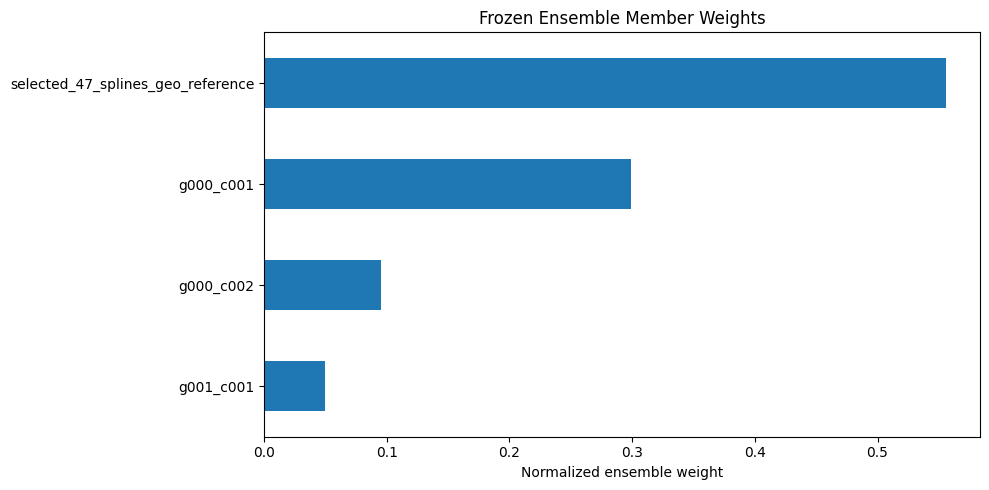

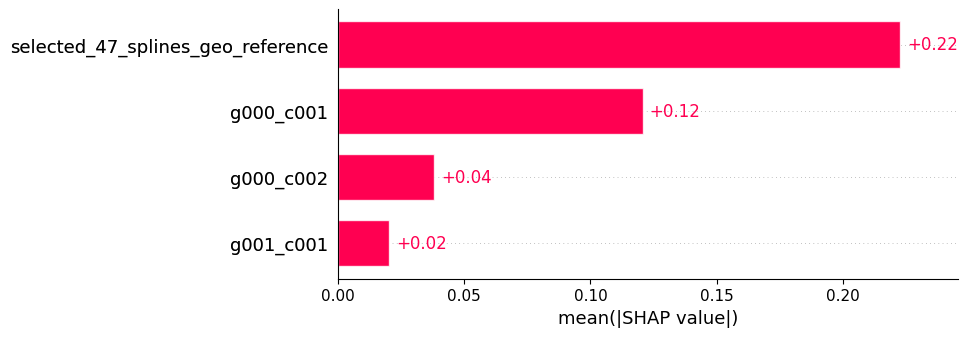

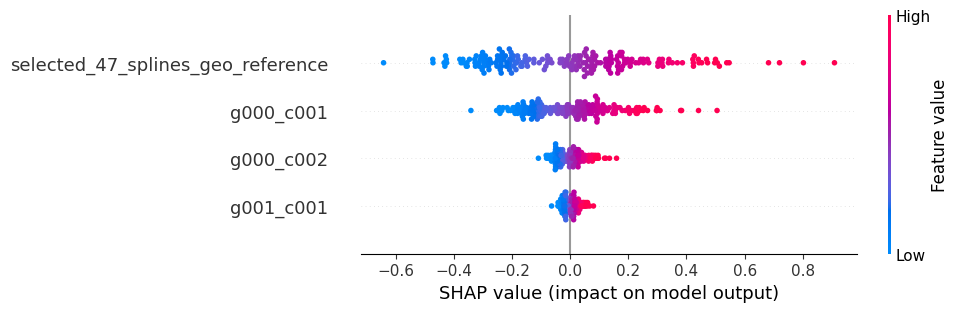

,ensemble_weight,mean_abs_shap,relative_shap_importance
selected_47_splines_geo_reference,0.55575,0.222865,0.554241
g000_c001,0.29925,0.120817,0.300458
g000_c002,0.09500,0.038132,0.094830
g001_c001,0.05000,0.020295,0.050471


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

import data
from models.save_model import load_model

# ============================================================
# 1. Load frozen ensemble
# ============================================================

ensemble = load_model(
    "off_market_release_candidate_full",
    track="off_market"
)

# ============================================================
# 2. Display actual ensemble weights
# ============================================================

weights = pd.Series(ensemble.weights, dtype=float)
weights = weights / weights.sum()

display(
    weights.sort_values(ascending=False)
    .rename("ensemble_weight")
    .to_frame()
)

weights.sort_values().plot.barh(
    figsize=(10, 5),
    title="Frozen Ensemble Member Weights"
)

plt.xlabel("Normalized ensemble weight")
plt.tight_layout()
plt.show()

# ============================================================
# 3. Collect predictions from individual ensemble members
# ============================================================

homes = data.load("off_market").head(200)
homes = data.hide_answers(homes, "off_market")

member_predictions = ensemble.predict_members(homes)

# Use log prices because the ensemble uses a geometric blend.
X = np.log(member_predictions)

# Match the exact ordering of the stored weights.
w = weights.reindex(X.columns).to_numpy()

# ============================================================
# 4. Calculate exact SHAP values of the blending function
# ============================================================

# Ensemble:
# log(P_ensemble) = sum(w_i * log(P_i))
#
# For an additive linear blend, using mean log predictions
# as the background:
#
# SHAP_i = w_i * (log(P_i) - mean(log(P_i)))

background = X.mean(axis=0)

shap_values = (X - background).to_numpy() * w

base_value = float(background.to_numpy() @ w)

explanation = shap.Explanation(
    values=shap_values,
    base_values=np.full(len(X), base_value),
    data=X.to_numpy(),
    feature_names=X.columns.tolist(),
)

# ============================================================
# 5. Global SHAP importance
# ============================================================

shap.plots.bar(explanation, max_display=len(X.columns))

# Distribution of member contributions across homes
shap.plots.beeswarm(explanation, max_display=len(X.columns))

# ============================================================
# 6. Compare weights against SHAP importance
# ============================================================

comparison = pd.DataFrame({
    "ensemble_weight": weights.reindex(X.columns),
    "mean_abs_shap": np.abs(shap_values).mean(axis=0),
})

comparison["relative_shap_importance"] = (
    comparison["mean_abs_shap"]
    / comparison["mean_abs_shap"].sum()
)

display(
    comparison.sort_values(
        "mean_abs_shap", ascending=False
    )
)

In [9]:
from models.ensemble_automl_factory import _text_provider

# Recover original vocabulary from every fitted ensemble member.
text_mappings = {}

for name, bundle in ensemble.members.items():
    text = _text_provider(bundle.feature_provider)

    if text is None:
        continue

    # Maps 'text_123' -> 'original word or phrase'
    mapping = text.text_feature_names

    text_mappings[name] = mapping

    print(f"{name}: {len(mapping)} vocabulary terms")

# Rename columns in the aggregated SHAP table.
# The same text column number can represent different terms
# across members, so rebuild the aggregation first.

renamed_shap = []

for name, shap_df in zip(ensemble.members, all_shap):
    mapping = text_mappings.get(name, {})

    readable = shap_df.rename(
        columns={
            col: f"remark: {mapping[col]}"
            for col in shap_df.columns
            if col in mapping
        }
    )

    renamed_shap.append(readable)

ensemble_shap_readable = renamed_shap[0].copy()

for frame in renamed_shap[1:]:
    ensemble_shap_readable = (
        ensemble_shap_readable.add(frame, fill_value=0)
    )

readable_importance = (
    ensemble_shap_readable.abs()
    .mean()
    .sort_values(ascending=False)
)

readable_table = pd.DataFrame({
    "mean_abs_shap": readable_importance,
    "relative_importance_pct": (
        100 * readable_importance / readable_importance.sum()
    )
})

display(readable_table.head(40))

selected_47_splines_geo_reference: 1000 vocabulary terms
g000_c001: 1000 vocabulary terms
g000_c002: 1000 vocabulary terms
g001_c001: 1000 vocabulary terms


,mean_abs_shap,relative_importance_pct
comp_log_price,0.228688,25.838784
community,0.121040,13.675988
lot_front,0.060573,6.843967
washrooms,0.058034,6.557128
square_feet,0.030971,3.499314
parking,0.023504,2.655598
months_since_2021,0.021676,2.449148
lot_area,0.021541,2.433826
house_type_name,0.019191,2.168333
extra_spline_2_3,0.018398,2.078724


Calculating SHAP: selected_47_splines_geo_reference
Calculating SHAP: g000_c001
Calculating SHAP: g000_c002
Calculating SHAP: g001_c001


,mean_abs_shap_log_price,relative_importance_pct
comp_log_price,0.228688,25.838784
community,0.121040,13.675988
lot_front,0.060573,6.843967
washrooms,0.058034,6.557128
square_feet,0.030971,3.499314
parking,0.023504,2.655598
months_since_2021,0.021676,2.449148
lot_area,0.021541,2.433826
house_type_name,0.019191,2.168333
extra_spline_2_3,0.018398,2.078724


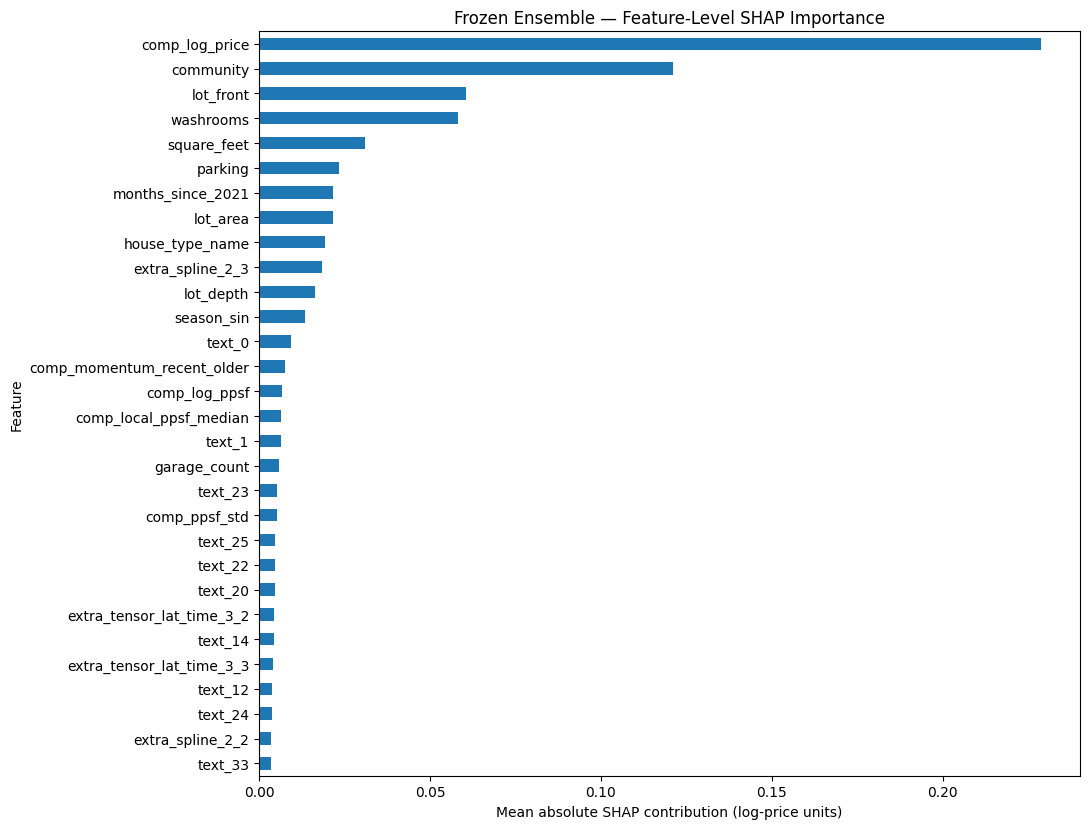

,member,feature,mean_abs_shap,ensemble_weight,weighted_importance
18,selected_47_splines_geo_reference,comp_log_price,0.252121,0.55575,0.140116
16,selected_47_splines_geo_reference,community,0.118879,0.55575,0.066067
228,g000_c001,comp_log_price,0.196797,0.29925,0.058892
226,g000_c001,community,0.125697,0.29925,0.037615
2,selected_47_splines_geo_reference,washrooms,0.056551,0.55575,0.031428
5,selected_47_splines_geo_reference,lot_front,0.049872,0.55575,0.027716
215,g000_c001,lot_front,0.076479,0.29925,0.022886
438,g000_c002,comp_log_price,0.231856,0.09500,0.022026
212,g000_c001,washrooms,0.059774,0.29925,0.017887
0,selected_47_splines_geo_reference,square_feet,0.023147,0.55575,0.012864


In [10]:


# ============================================================
# CONFIGURATION
# ============================================================

N_SAMPLES = 200
TOP_FEATURES = 30

homes = data.load("off_market").head(N_SAMPLES)
homes = data.hide_answers(homes, "off_market")

# Normalize the ensemble's geometric-blending weights
weights = pd.Series(ensemble.weights, dtype=float)
weights /= weights.sum()

# ============================================================
# COMPUTE FEATURE-LEVEL SHAP FOR EACH MEMBER
# ============================================================

all_shap = []
all_importance = []

for name, bundle in ensemble.members.items():

    print(f"Calculating SHAP: {name}")

    # Every ensemble member has its own fitted feature provider.
    provider = bundle.feature_provider
    member = bundle.members[name]

    X = provider.transform(homes)
    X = X.loc[:, list(member.selected_columns)]

    explainer = shap.TreeExplainer(member.estimator)
    values = np.asarray(explainer.shap_values(X))

    # Each member contributes to the final log-price prediction
    # according to its ensemble weight.
    weighted_values = values * weights[name]

    shap_df = pd.DataFrame(
        weighted_values,
        index=homes.index,
        columns=X.columns,
    )

    all_shap.append(shap_df)

    all_importance.append(pd.DataFrame({
        "member": name,
        "feature": X.columns,
        "mean_abs_shap": np.abs(values).mean(axis=0),
        "ensemble_weight": weights[name],
        "weighted_importance": (
            np.abs(values).mean(axis=0) * weights[name]
        ),
    }))

# ============================================================
# AGGREGATE FEATURES ACROSS ENSEMBLE MEMBERS
# ============================================================

# Same-named features from different members are added together.
# Missing features in a member contribute zero.
ensemble_shap = all_shap[0].copy()

for frame in all_shap[1:]:
    ensemble_shap = ensemble_shap.add(frame, fill_value=0)

# Global importance of each feature in the final ensemble.
feature_importance = (
    ensemble_shap.abs()
    .mean()
    .sort_values(ascending=False)
)

feature_table = pd.DataFrame({
    "mean_abs_shap_log_price": feature_importance,
    "relative_importance_pct": (
        100 * feature_importance / feature_importance.sum()
    ),
})

display(feature_table.head(TOP_FEATURES))

# ============================================================
# PLOT
# ============================================================

top = feature_importance.head(TOP_FEATURES)

plt.figure(figsize=(11, max(6, TOP_FEATURES * 0.28)))

top.iloc[::-1].plot.barh()

plt.title("Frozen Ensemble — Feature-Level SHAP Importance")
plt.xlabel("Mean absolute SHAP contribution (log-price units)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

# ============================================================
# OPTIONAL: INDIVIDUAL-MEMBER FEATURE IMPORTANCE
# ============================================================

member_importance = pd.concat(all_importance, ignore_index=True)

display(
    member_importance.sort_values(
        "weighted_importance",
        ascending=False
    ).head(30)
)